# STATE Codex R2 — Baseline cross-cell-line distance

All custom calculations are executable inline. Run the six sections in order. Model evaluation uses the pinned public STATE releases. Use Python 3.11 with numpy 1.26.4, pandas 2.2.2, scipy 1.13.1, pyarrow 16.1.0, matplotlib 3.9.4, h5py 3.11.0, fsspec, aiohttp, IPython and ipykernel. `STATE_R2_INPUTS` may point at a verified raw-input cache.

## 1. Data source and acquisition

The URLs, sizes and SHA-256 values below identify the public input objects.

In [1]:
from pathlib import Path
import os,json,hashlib,time,platform,urllib.request,urllib.parse,ast,tomllib,re,zipfile,itertools
os.environ['OMP_NUM_THREADS']='1';os.environ['OPENBLAS_NUM_THREADS']='1';os.environ['MKL_NUM_THREADS']='1'
import numpy as np
import pandas as pd
import pyarrow.dataset as ds
import fsspec,h5py
from scipy.stats import spearmanr,pearsonr,rankdata
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display,Image
START=time.time()
DATA=Path(os.environ.get('STATE_R2_INPUTS','state_r2_inputs')).resolve(); DATA.mkdir(parents=True,exist_ok=True)
ROOT=Path('test-02_outputs').resolve();ROOT.mkdir(parents=True,exist_ok=True)
CELLS={'C32':'C32','HOP62':'HOP62','HepG2/C3A':'HepG2-C3A','Hs 766T':'Hs 766T','PANC-1':'PANC-1'}
CTX=['k562','jurkat','hepg2','rpe1']

from io import BytesIO
from IPython.display import Image
def display_figure(figure):
    buffer=BytesIO()
    figure.savefig(buffer,format='png',dpi=140,bbox_inches='tight')
    display(Image(data=buffer.getvalue()))


In [2]:
SOURCES = [{'path': 'metadata/depmap_24q4_protein_coding_tpm_logp1.csv',
  'url': 'https://ndownloader.figshare.com/files/51065489',
  'bytes': 506628654,
  'sha256': '2a71dc94110efcc0221eae821bb93a9f03b54bea16f005818911a09d33383d56'},
 {'path': 'metadata/depmap_24q4_model.csv',
  'url': 'https://ndownloader.figshare.com/files/51065297',
  'bytes': 645696,
  'sha256': 'b7a0c1385e6cef30132b56aff61f1261d11e3f490490b355c430d32ee0dbdcfa'},
 {'path': 'metadata/hpa_rna_celline.tsv.zip',
  'url': 'https://www.proteinatlas.org/download/tsv/rna_celline.tsv.zip',
  'bytes': 205861141,
  'sha256': 'e5b11779308c2720cfe89d9cb19932ad4c0c3fea0fa37e8c61a14d501995852a'},
 {'path': 'ST-SE-Replogle/zeroshot/k562/eval_best.ckpt/k562_pred_de.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/k562/eval_best.ckpt/k562_pred_de.csv',
  'bytes': 344243692,
  'sha256': '230ac1f1f8342d0c7f563166b6e8f9afeae6a02a62d0b737fda64168dde49ba0'},
 {'path': 'ST-SE-Replogle/zeroshot/k562/eval_best.ckpt/k562_real_de.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/k562/eval_best.ckpt/k562_real_de.csv',
  'bytes': 343530568,
  'sha256': 'a367d89432c430f6bef3d3efd23c0a543144c1c55bb94e64c818c97de2cbd1dd'},
 {'path': 'ST-SE-Replogle/zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'bytes': 528013,
  'sha256': 'eaf22cc6169fa98ab90913366529db232ac2109fe421599f66d47b14ffd183b3'},
 {'path': 'ST-SE-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_pred_de.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/jurkat/eval_best.ckpt/jurkat_pred_de.csv',
  'bytes': 380905134,
  'sha256': 'fd3422f18087eaf8357112bc0fd87faa8f95ed2a9ad95f0e7c4107d52754a9ca'},
 {'path': 'ST-SE-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_real_de.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/jurkat/eval_best.ckpt/jurkat_real_de.csv',
  'bytes': 380988038,
  'sha256': '68fcb087841310e0e435b1bf63f1dbd69fc73c849d31a288f01d9d7ce40982ff'},
 {'path': 'ST-SE-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'bytes': 568100,
  'sha256': '372db67f297565e5542cac1bda688586c07e03e92a999bea953a9df812ba5317'},
 {'path': 'ST-SE-Replogle/zeroshot/hepg2/eval_best.ckpt/hepg2_pred_de.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/hepg2/eval_best.ckpt/hepg2_pred_de.csv',
  'bytes': 332206930,
  'sha256': '88c1e92c75525dcc6bcb5bd74938f91841d2654a92b8b17da8992f28b9f8bb42'},
 {'path': 'ST-SE-Replogle/zeroshot/hepg2/eval_best.ckpt/hepg2_real_de.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/hepg2/eval_best.ckpt/hepg2_real_de.csv',
  'bytes': 331857105,
  'sha256': 'c0a9582aeec67230424e4d95fd26f5c2a6d9e841c13f804d46de1b74aaeddff7'},
 {'path': 'ST-SE-Replogle/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'bytes': 509894,
  'sha256': '9b7b329faa11cfdfbbac37ad571bdf47e8af7f988d61561eab51d80dce9d643a'},
 {'path': 'ST-SE-Replogle/zeroshot/rpe1/eval_best.ckpt/rpe1_pred_de.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/rpe1/eval_best.ckpt/rpe1_pred_de.csv',
  'bytes': 371395462,
  'sha256': 'b73237aad873fa97ddb79dcf055a3fb36d2f0a6ca13730af08fd36b04e83a126'},
 {'path': 'ST-SE-Replogle/zeroshot/rpe1/eval_best.ckpt/rpe1_real_de.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/rpe1/eval_best.ckpt/rpe1_real_de.csv',
  'bytes': 373246770,
  'sha256': '8656cf2495e712f1d05110e702c70cbba7aa281c93075b814be0078cd53eb308'},
 {'path': 'ST-SE-Replogle/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'bytes': 535692,
  'sha256': 'ce7034b9e7af7255f44347ac9fdcbdd41e13b8ce674cab3c2700c0b41a1b1ffa'},
 {'path': 'ST-HVG-Replogle/zeroshot/k562/eval_best.ckpt/k562_pred_de.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/k562/eval_best.ckpt/k562_pred_de.csv',
  'bytes': 321344933,
  'sha256': '89b5d659f021eb9d64c41e282994453c3a7e968370cf62cef09ca3b3f7408a56'},
 {'path': 'ST-HVG-Replogle/zeroshot/k562/eval_best.ckpt/k562_real_de.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/k562/eval_best.ckpt/k562_real_de.csv',
  'bytes': 343530568,
  'sha256': 'a367d89432c430f6bef3d3efd23c0a543144c1c55bb94e64c818c97de2cbd1dd'},
 {'path': 'ST-HVG-Replogle/zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'bytes': 538095,
  'sha256': '8bd145c4667e03c9e367079dcfb38126e4e1f06b562f8a3fa6d1eaa1d0ba5821'},
 {'path': 'ST-HVG-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_pred_de.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/jurkat/eval_best.ckpt/jurkat_pred_de.csv',
  'bytes': 344695065,
  'sha256': 'a99a847e2bc783a73a64ea2c34ae065198b33ffc855b01d7d56d3fc5b31e694e'},
 {'path': 'ST-HVG-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_real_de.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/jurkat/eval_best.ckpt/jurkat_real_de.csv',
  'bytes': 380988038,
  'sha256': '68fcb087841310e0e435b1bf63f1dbd69fc73c849d31a288f01d9d7ce40982ff'},
 {'path': 'ST-HVG-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'bytes': 582103,
  'sha256': '3efc817549bbf24edd6e427fb99466f58de8fadb3a4b4335523f5cfac1bc8098'},
 {'path': 'ST-HVG-Replogle/zeroshot/hepg2/eval_best.ckpt/hepg2_pred_de.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/hepg2/eval_best.ckpt/hepg2_pred_de.csv',
  'bytes': 299683790,
  'sha256': '138ee80b5ecd3bec4badd4e91466e74467e55c6e3247643e33bf65378c8079f1'},
 {'path': 'ST-HVG-Replogle/zeroshot/hepg2/eval_best.ckpt/hepg2_real_de.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/hepg2/eval_best.ckpt/hepg2_real_de.csv',
  'bytes': 331857105,
  'sha256': 'c0a9582aeec67230424e4d95fd26f5c2a6d9e841c13f804d46de1b74aaeddff7'},
 {'path': 'ST-HVG-Replogle/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'bytes': 506756,
  'sha256': '0c930ad038b56c6f43d25896a15cd68e121d8902e5457718b4dfc9f163f10604'},
 {'path': 'ST-HVG-Replogle/zeroshot/rpe1/eval_best.ckpt/rpe1_pred_de.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/rpe1/eval_best.ckpt/rpe1_pred_de.csv',
  'bytes': 347045906,
  'sha256': 'ae1a84742a3230e35414e38e2f289d5f7d3abd1b2f14a10683b16c134657aecc'},
 {'path': 'ST-HVG-Replogle/zeroshot/rpe1/eval_best.ckpt/rpe1_real_de.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/rpe1/eval_best.ckpt/rpe1_real_de.csv',
  'bytes': 373246770,
  'sha256': '8656cf2495e712f1d05110e702c70cbba7aa281c93075b814be0078cd53eb308'},
 {'path': 'ST-HVG-Replogle/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'bytes': 575323,
  'sha256': 'c187b3a026c8381a84acbe5035efa30947a6774c82a6519749b1b37e85fdd14d'}]


In [3]:
def sha(p):
    h=hashlib.sha256()
    with open(p,'rb') as f:
        for b in iter(lambda:f.read(8388608),b''):h.update(b)
    return h.hexdigest()
def checked(root,rel):
    x=next(x for x in SOURCES if x['path']==rel);p=DATA/rel
    if not p.exists() or p.stat().st_size!=x['bytes'] or sha(p)!=x['sha256']:raise ValueError('Input checksum mismatch: '+rel)
    return p
for x in SOURCES:
    p=DATA/x['path'];p.parent.mkdir(parents=True,exist_ok=True)
    if not p.exists():
        temp=p.with_suffix(p.suffix+'.part')
        req=urllib.request.Request(x['url'],headers={'User-Agent':'STATE-notebook/1.0'})
        with urllib.request.urlopen(req,timeout=180) as source,temp.open('wb') as target:
            while b:=source.read(8388608):target.write(b)
        if temp.stat().st_size!=x['bytes'] or sha(temp)!=x['sha256']:raise ValueError('Downloaded source identity mismatch: '+x['path'])
        temp.replace(p)
    checked(ROOT,x['path'])
print('Verified public input files:',len(SOURCES))


Verified public input files: 27


## 2. Data processing

In [4]:
def sha(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(8 * 1024 * 1024), b''):
            h.update(b)
    return h.hexdigest()

def dump(path, obj):
    p = Path(path)
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(json.dumps(obj, indent=2, default=lambda x: x.item() if isinstance(x, np.generic) else str(x), allow_nan=False) + '\n')

def zscore(x):
    x = np.asarray(x, dtype=float)
    s = x.std(ddof=0)
    if not s > 0:
        raise ValueError('Constant predictor')
    return (x - x.mean()) / s

def fisher(x):
    return np.arctanh(np.clip(np.asarray(x, float), -1 + 1e-07, 1 - 1e-07))

def cluster_fit(d, y, x, cluster, adjust=(), fixed=(), cluster_fixed=False, draws=10000, seed=20260715):
    cols = [y, x, cluster, *adjust, *fixed]
    d = d.dropna(subset=cols).copy()
    X = [np.ones(len(d)), zscore(d[x])]
    names = ['intercept', x]
    for c in adjust:
        v = np.asarray(d[c], float)
        if np.std(v) > 0:
            X.append(zscore(v))
            names.append(c)
    for c in fixed:
        for val in sorted(d[c].unique())[1:]:
            X.append((d[c] == val).astype(float).values)
            names.append(f'{c}={val}')
    X = np.column_stack(X)
    Y = d[y].to_numpy(float)
    groups = sorted(d[cluster].unique())
    codes = pd.Categorical(d[cluster], categories=groups).codes
    if cluster_fixed:
        for j in range(len(groups)):
            sel = codes == j
            X[sel] -= X[sel].mean(axis=0)
            Y[sel] -= Y[sel].mean()
        X = X[:, 1:]
        names = names[1:]
        axis_idx = 0
    else:
        axis_idx = 1
    gxx = np.zeros((len(groups), X.shape[1], X.shape[1]))
    gxy = np.zeros((len(groups), X.shape[1]))
    for j in range(len(groups)):
        sel = codes == j
        gxx[j] = X[sel].T @ X[sel]
        gxy[j] = X[sel].T @ Y[sel]
    coefficient = np.linalg.lstsq(X, Y, rcond=None)[0]
    rng = np.random.default_rng(seed)
    boot = []
    for start in range(0, draws, 100):
        n = min(100, draws - start)
        w = rng.multinomial(len(groups), np.full(len(groups), 1 / len(groups)), size=n)
        xx = np.einsum('bg,gij->bij', w, gxx)
        xy = w @ gxy
        for a, b in zip(xx, xy):
            boot.append(np.linalg.lstsq(a, b, rcond=None)[0][axis_idx])
    return (dict(n=len(d), clusters=len(groups), coefficient=float(coefficient[axis_idx]), ci95=np.quantile(boot, [0.025, 0.975]).tolist(), draws=draws, seed=seed, design_columns=names, cluster_fixed_effect=cluster_fixed, axis_standardization='population SD on all analyzed rows', coefficients=dict(zip(names, coefficient))), np.asarray(boot))

def curve(d, level, score, cluster, draws=10000, seed=20260715):
    groups = sorted(d[cluster].unique())
    levels = sorted(d[level].unique())
    rng = np.random.default_rng(seed)
    w = rng.multinomial(len(groups), np.full(len(groups), 1 / len(groups)), size=draws)
    rows = []
    boot = {}
    for v in levels:
        q = d[d[level] == v]
        g = q.groupby(cluster)[score].agg(['sum', 'count']).reindex(groups, fill_value=0)
        b = w @ g['sum'].values / (w @ g['count'].values)
        boot[str(v)] = b
        rows.append(dict(level=v, n=len(q), clusters=q[cluster].nunique(), mean=q[score].mean(), ci_low=np.quantile(b, 0.025), ci_high=np.quantile(b, 0.975)))
    return (pd.DataFrame(rows), boot)

def decode(a):
    if a.dtype.kind in ['O', 'S', 'U']:
        return np.array([x.decode() if isinstance(x, bytes) else str(x) for x in a], dtype=object)
    return a

def field(group, name):
    x = group[name]
    if isinstance(x, h5py.Dataset):
        return decode(x[:])
    cats = decode(x['categories'][:])
    codes = x['codes'][:]
    return np.array([cats[c] if c >= 0 else None for c in codes], dtype=object)

In [5]:
OBSERVATION_SOURCES=[{'path': 'ST-SE-Replogle/zeroshot/k562/eval_best.ckpt/adata_real.h5ad', 'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/k562/eval_best.ckpt/adata_real.h5ad', 'bytes': 3079506036, 'sha256': '6951f4bffb532950c447e8dc300b2f42ab381c854273327f8cd38b84cfa4eb42', 'evidence': 'Pinned original release; observation-only range extraction'}, {'path': 'ST-SE-Replogle/zeroshot/jurkat/eval_best.ckpt/adata_real.h5ad', 'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/jurkat/eval_best.ckpt/adata_real.h5ad', 'bytes': 3012265108, 'sha256': '9df1a21e3b159fa3900a32dd8bd6b4d6dd8750838014d1d3997932d7cedc9673', 'evidence': 'Pinned original release; observation-only range extraction'}, {'path': 'ST-SE-Replogle/zeroshot/hepg2/eval_best.ckpt/adata_real.h5ad', 'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/hepg2/eval_best.ckpt/adata_real.h5ad', 'bytes': 1577727376, 'sha256': '75f79feff37c4334559ea88c1e2a27acd306eb7dee5a2e25f37c4860014ca2b9', 'evidence': 'Pinned original release; observation-only range extraction'}, {'path': 'ST-SE-Replogle/zeroshot/rpe1/eval_best.ckpt/adata_real.h5ad', 'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/rpe1/eval_best.ckpt/adata_real.h5ad', 'bytes': 2837025870, 'sha256': 'f3363768db24b7eee9cb55507443366f8e15b6f9e5731ac415f533b757a5b5b1', 'evidence': 'Pinned original release; observation-only range extraction'}]
OBSERVATION_TABLE_HASHES={'k562': '1fabb9c169d62406377c3724e7208474f4fac2bea75bcc4533bffc3c4ce9bd80', 'jurkat': '0e82c9f308e2658359b86c0d77460a532993f33ed903df7488c3f1b940ad804a', 'hepg2': '1c4b0d674e090ccf8386ff44d4ef95771ddcbd8b8a9985087b851b69e5b11be6', 'rpe1': 'd36506fa9c0a47adf5a385ab327825e2abe5b99ef4e9e9eefe5c37c2bb876c4a'}

In [6]:
fs=fsspec.filesystem('http');count_parts=[]
for x in OBSERVATION_SOURCES:
    context=x['path'].split('/')[2];p=DATA/'observation_extracts'/f'{context}.parquet';p.parent.mkdir(parents=True,exist_ok=True)
    if p.exists() and sha(p)==OBSERVATION_TABLE_HASHES[context]:
        observations=pd.read_parquet(p)
    else:
        with fs.open(x['url'],'rb',block_size=262144,cache_type='blockcache',size=x['bytes']) as f:
            with h5py.File(f,'r') as h:observations=pd.DataFrame({k:field(h['obs'],k) for k in ['gene','cell_line','gem_group','pert_cell_barcode','ctrl_cell_barcode']})
        observations.to_parquet(p,index=False)
    counts=observations.groupby('gene',observed=True).agg(n_treated=('pert_cell_barcode','nunique'),n_control=('ctrl_cell_barcode','nunique'),n_rows=('gene','size')).reset_index().rename(columns={'gene':'perturbation'})
    counts['context']=context;count_parts.append(counts)
counts=pd.concat(count_parts,ignore_index=True)
out=ROOT/'computed/replogle';out.mkdir(parents=True,exist_ok=True);counts.to_csv(out/'cell_counts.csv',index=False)
display(counts.groupby('context')[['n_treated','n_control']].agg(['min','median','max']))


n_treated               n_control             
              min median    max       min median   max
context                                               
hepg2          30   53.0   4976        29   53.0  2574
jurkat         30   88.0  12013        30   88.0  6009
k562           30  109.0  10691        30  109.0  5777
rpe1           30   78.0  11485        30   77.5  5871

## 3. Axis definition and level construction

For baseline distance, intersect DepMap and HPA gene symbols, collapse duplicate gene symbols by arithmetic mean, and use the coordinatewise median of six RPE1 clones. The axis is mean 1 − Spearman correlation to the other three contexts. For magnitude, use the other-context mean observed effect RMS; the test context never supplies its own expected effect.

In [7]:
def axes(root):
    out = root / 'computed/replogle'
    out.mkdir(parents=True, exist_ok=True)
    ep = checked(root, 'metadata/depmap_24q4_protein_coding_tpm_logp1.csv')
    hp = checked(root, 'metadata/hpa_rna_celline.tsv.zip')
    mp = checked(root, 'metadata/depmap_24q4_model.csv')
    ids = {'k562': ['ACH-000551'], 'jurkat': ['ACH-000995'], 'hepg2': ['ACH-000739'], 'rpe1': [f'ACH-00246{i}' for i in range(2, 8)]}
    wanted = set(sum(ids.values(), []))
    parts = []
    for chunk in pd.read_csv(ep, index_col=0, chunksize=200):
        part = chunk.loc[chunk.index.intersection(wanted)]
        if len(part):
            parts.append(part)
    e = pd.concat(parts)
    e.columns = [re.sub('\\s+\\(.*\\)$', '', str(x)) for x in e.columns]
    e = e.T.groupby(level=0, sort=True).mean().T
    if set(e.index) != wanted:
        raise ValueError('Original DepMap context map incomplete')
    with zipfile.ZipFile(hp) as z:
        names = [n for n in z.namelist() if n.endswith('.tsv')]
        if len(names) != 1:
            raise ValueError('Unexpected HPA archive')
        parts = []
        for h in pd.read_csv(z.open(names[0]), sep='\t', chunksize=500000):
            parts.append(h[h['Cell line'].isin(['K-562', 'JURKAT', 'Hep-G2', 'hTERT-RPE1', 'Jurkat E6.1'])])
    h = pd.concat(parts)
    h = h.pivot_table(index='Cell line', columns='Gene name', values='nTPM', aggfunc='mean')
    genes = sorted(set(e.columns) & set(h.columns))
    pd.Series(genes, name='gene').to_csv(out / 'prospective_genes.csv', index=False)
    de = np.stack([e.loc[ids[c], genes].median(axis=0).values for c in CTX])
    names = ['K-562', 'JURKAT', 'Hep-G2', 'hTERT-RPE1']
    ha = np.log2(1 + h.loc[names, genes].values)
    hs = ha.copy()
    hs[1] = np.log2(1 + h.loc['Jurkat E6.1', genes].values)

    def dist(x):
        if not np.isfinite(x).all():
            raise ValueError('Nonfinite prospective expression')
        return 1 - np.corrcoef(rankdata(x, axis=1, method='average'))
    dp, dh, ds = (dist(de), dist(ha), dist(hs))
    rows = []
    for i, c in enumerate(CTX):
        other = np.arange(4) != i
        rows.append(dict(context=c, distance=dp[i, other].mean(), nearest_distance=dp[i, other].min(), hpa_distance=dh[i, other].mean(), hpa_e61_distance=ds[i, other].mean()))
    d = pd.DataFrame(rows)
    d['level'] = d.distance.rank(method='first').astype(int)
    d.to_csv(out / 'axis.csv', index=False)
    for n, v in [('depmap', dp), ('hpa', dh), ('hpa_e61', ds)]:
        pd.DataFrame(v, index=CTX, columns=CTX).to_csv(out / f'{n}_pairwise.csv')
    summary = dict(genes=len(genes), nearest_unique_values=int(np.unique(np.round(d.nearest_distance, 12)).size), panel_mean_unique_values=int(np.unique(np.round(d.distance, 12)).size), hpa_rank_correlation=float(spearmanr(d.distance, d.hpa_distance).statistic), hpa_e61_rank_correlation=float(spearmanr(d.distance, d.hpa_e61_distance).statistic), definition='Mean of 1−Spearman to the other three contexts')
    dump(out / 'axis_summary.json', summary)
    return d
axis=axes(ROOT)
display(axis)

,context,distance,nearest_distance,hpa_distance,hpa_e61_distance,level
0,k562,0.180460,0.151676,0.185824,0.187261,1
1,jurkat,0.183549,0.151676,0.192026,0.203245,2
2,hepg2,0.194748,0.191412,0.198047,0.200703,3
3,rpe1,0.195752,0.191412,0.211327,0.218453,4


## 4. Model results and released scores

Compute signed log2 fold changes directly from the released gene-level tables. Nonpositive fold changes are nonfinite. Collapse duplicate target–gene rows by mean log2 fold change. The reference predicts the same perturbation using the mean observed change in the other three contexts.

In [8]:
def de_matrix(p):
    d = pd.read_csv(p, usecols=['target', 'feature', 'fold_change', 'fdr'])
    d = d[d.target != 'non-targeting'].copy()
    d['lfc'] = np.log2(d.fold_change.where(d.fold_change > 0))
    d['significant'] = (d.fdr < 0.05).astype(int)
    q = d.groupby(['target', 'feature'], sort=True).agg(lfc=('lfc', 'mean'), significant=('significant', 'max')).reset_index()
    mat = q.pivot(index='target', columns='feature', values='lfc')
    nd = q.groupby('target').significant.sum()
    return (mat, nd)

def row_spearman(a, b):
    out = []
    for x, y in zip(a, b):
        f = np.isfinite(x) & np.isfinite(y)
        out.append(float(spearmanr(x[f], y[f]).statistic) if f.sum() >= 20 else np.nan)
    return np.asarray(out)

def scores(root):
    out = root / 'computed/replogle'
    out.mkdir(parents=True, exist_ok=True)
    sources = []
    mats = {}
    sig = {}
    availability = []
    for model in ['ST-SE-Replogle', 'ST-HVG-Replogle']:
        for c in CTX:
            for kind in ['real', 'pred']:
                p = checked(root, f'{model}/zeroshot/{c}/eval_best.ckpt/{c}_{kind}_de.csv')
                sources.append(p)
                print('REPL DE', model, c, kind, flush=True)
                mat, n = de_matrix(p)
                mats[model, c, kind] = mat
                sig[model, c, kind] = n
                availability.extend((dict(model=model, context=c, kind=kind, perturbation=g) for g in mat.index))
    primary_sets = [set(mats['ST-SE-Replogle', c, k].index) for c in CTX for k in ['real', 'pred']]
    balanced = set.intersection(*primary_sets)
    union = set.union(*primary_sets)
    remaining = union - balanced
    elig = []
    for p in sorted(union):
        row = dict(perturbation=p, discovery=p in balanced, confirmation_candidate=p in remaining)
        for c in CTX:
            row[c + '_real'] = p in mats['ST-SE-Replogle', c, 'real'].index
            row[c + '_pred'] = p in mats['ST-SE-Replogle', c, 'pred'].index
        row['confirmation_eligible'] = p in remaining and all((row[c + '_' + k] for c in CTX for k in ['real', 'pred']))
        elig.append(row)
    pd.DataFrame(elig).to_csv(out / 'A2_eligibility.csv', index=False)
    pd.DataFrame(availability).to_csv(out / 'released_condition_availability.csv', index=False)
    genes = sorted(set.intersection(*(set(m.columns) for m in mats.values())), key=str)
    perts = sorted(balanced)
    real = {c: mats['ST-SE-Replogle', c, 'real'].reindex(index=perts, columns=genes).values for c in CTX}
    rows = []
    for c in CTX:
        truth = real[c]
        other = [real[x] for x in CTX if x != c]
        ref = np.mean(other, axis=0)
        rms = np.sqrt(np.nanmean(truth ** 2, axis=1))
        expected = np.mean([np.sqrt(np.nanmean(x ** 2, axis=1)) for x in other], axis=0)
        se = row_spearman(truth, mats['ST-SE-Replogle', c, 'pred'].reindex(index=perts, columns=genes).values)
        hv = row_spearman(truth, mats['ST-HVG-Replogle', c, 'pred'].reindex(index=perts, columns=genes).values)
        rr = row_spearman(truth, ref)
        for j, p in enumerate(perts):
            rows.append(dict(context=c, perturbation=p, state_se=se[j], state_hvg=hv[j], reference=rr[j], effect_rms=rms[j], expected_rms=expected[j], n_de=int(sig['ST-SE-Replogle', c, 'real'][p]), features=int(np.isfinite(truth[j]).sum())))
    d = pd.DataFrame(rows)
    valid = d.groupby('perturbation').apply(lambda x: len(x) == 4 and np.isfinite(x[['state_se', 'state_hvg', 'reference']].values).all(), include_groups=False)
    d = d[d.perturbation.isin(valid[valid].index)].copy()
    d.to_csv(out / 'unit_scores.csv', index=False)
    summary = dict(primary_balanced_perturbations=len(balanced), finite_balanced_perturbations=d.perturbation.nunique(), common_output_features=len(genes), disjoint_candidates=len(remaining), eligible_disjoint_candidates=sum((x['confirmation_eligible'] for x in elig)))
    dump(out / 'score_summary.json', summary)
    return d
units=scores(ROOT)
display(units.head())

REPL DE ST-SE-Replogle k562 real


REPL DE ST-SE-Replogle k562 pred


REPL DE ST-SE-Replogle jurkat real


REPL DE ST-SE-Replogle jurkat pred


REPL DE ST-SE-Replogle hepg2 real


REPL DE ST-SE-Replogle hepg2 pred


... (7 outputs left out)

REPL DE ST-HVG-Replogle hepg2 pred


REPL DE ST-HVG-Replogle rpe1 real


REPL DE ST-HVG-Replogle rpe1 pred


,context,perturbation,state_se,state_hvg,reference,effect_rms,expected_rms,n_de,features
0,k562,AAAS,-0.002881,0.023888,-0.041077,0.179836,0.346125,9,2000
1,k562,AARS,0.304736,0.341317,0.367937,0.694914,0.923523,260,2000
2,k562,ABCB7,0.150422,0.156359,0.225862,0.212345,0.548193,81,2000
3,k562,ABHD11,-0.021957,0.021292,0.025904,0.413468,0.408624,13,2000
4,k562,ACTR1B,0.020242,-0.033335,0.011623,0.175968,0.291761,4,2000


## 5. Curves and controls

In [9]:
def analyze(root, draws=10000):
    out = root / 'computed/replogle'
    axis = pd.read_csv(out / 'axis.csv')
    d = pd.read_csv(out / 'unit_scores.csv').merge(axis, on='context', validate='many_to_one')
    counts = pd.read_csv(out / 'cell_counts.csv')
    d = d.merge(counts, on=['context', 'perturbation'], validate='one_to_one')
    for c in ['effect_rms', 'n_de', 'n_treated', 'n_control']:
        d['log_' + c] = np.log1p(d[c])
    fits = {}
    cvs = []
    for metric in ['state_se', 'state_hvg', 'reference']:
        d['z_' + metric] = fisher(d[metric])
        fit, boot = cluster_fit(d, 'z_' + metric, 'distance', 'perturbation', draws=draws, seed=20260715)
        fits[metric] = fit
        cv, _ = curve(d, 'level', metric, 'perturbation', draws, 20260715)
        cv['metric'] = metric
        cvs.append(cv)
    paired, _ = cluster_fit(d, 'z_state_se', 'distance', 'perturbation', adjust=['log_effect_rms', 'log_n_de', 'log_n_treated', 'log_n_control'], cluster_fixed=True, draws=draws, seed=20260715)
    fits['adjusted_state_se'] = paired
    adj, _ = cluster_fit(d, 'z_state_se', 'distance', 'perturbation', adjust=['log_effect_rms', 'log_n_de', 'log_n_treated', 'log_n_control'], draws=draws, seed=20260715)
    fits['adjusted_state_se_pooled_sensitivity'] = adj
    context_means = d.groupby('context').z_state_se.mean().reindex(CTX).values
    x = axis.set_index('context').loc[CTX, 'distance'].values
    perm = []
    for p in itertools.permutations(x):
        perm.append(float(np.dot(zscore(p), context_means - context_means.mean()) / 4))
    fits['exact_context_permutation'] = dict(n=24, one_sided_p=float(np.mean(np.array(perm) <= fits['state_se']['coefficient'] + 1e-12)), slopes=perm)
    pd.concat(cvs, ignore_index=True).to_csv(out / 'distance_curve.csv', index=False)
    d.to_csv(out / 'distance_units.csv', index=False)
    dump(out / 'distance_summary.json', fits)
    d['weakness'] = -np.log1p(d.expected_rms)
    d['magnitude_level'] = 0
    for c, q in d.groupby('context'):
        ix = q.sort_values(['expected_rms', 'perturbation'], ascending=[False, True], kind='mergesort').index
        d.loc[ix, 'magnitude_level'] = np.floor(np.arange(len(ix)) * 5 / len(ix)).astype(int) + 1
    q = d[['expected_rms', 'weakness', 'state_se']] - d.groupby('context')[['expected_rms', 'weakness', 'state_se']].transform('mean')
    magfit, _ = cluster_fit(d, 'z_state_se', 'weakness', 'perturbation', fixed=['context'], draws=draws, seed=20260715)
    magcv, _ = curve(d, 'magnitude_level', 'state_se', 'perturbation', draws, 20260715)
    magcv.to_csv(out / 'magnitude_curve.csv', index=False)
    d.to_csv(out / 'magnitude_units.csv', index=False)
    eligibility = pd.read_csv(out / 'A2_eligibility.csv')
    summary = dict(expected_rms_context_residual_pearson=float(pearsonr(q.expected_rms, q.state_se).statistic), negative_log1p_rms_context_residual_pearson=float(pearsonr(q.weakness, q.state_se).statistic), fit=magfit, disjoint_candidates=int(eligibility.confirmation_candidate.sum()), eligible_confirmation_candidates=int(eligibility.confirmation_eligible.sum()), decision='No confirmation outcome test: complete-panel eligibility produced no disjoint candidates.')
    dump(out / 'magnitude_summary.json', summary)
    return fits, summary

fits,magnitude=analyze(ROOT,10000)

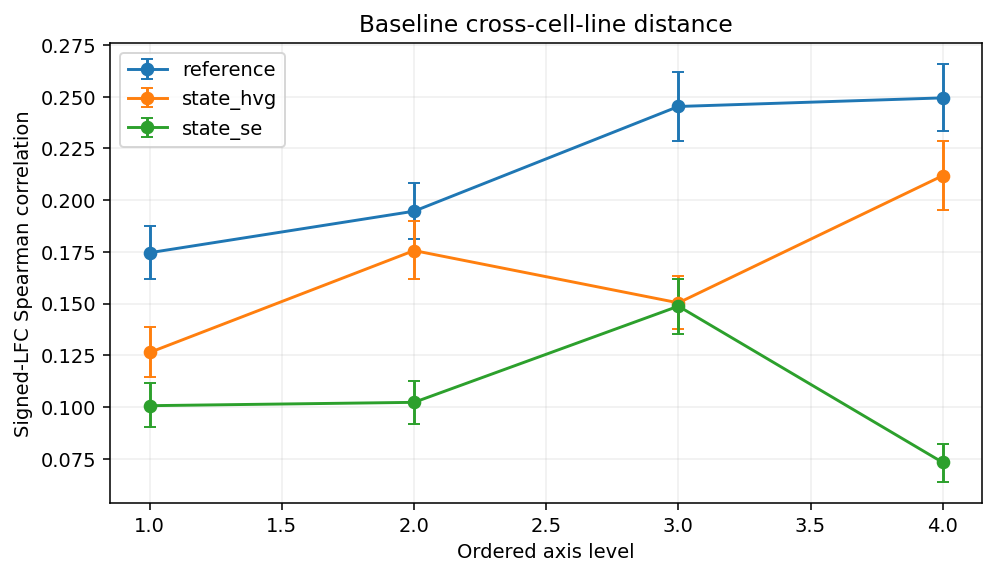

,fit,n,clusters,coefficient,ci95,draws,seed,design_columns,cluster_fixed_effect,axis_standardization,coefficients
0,state_se,2552,638,0.003635,"[0.0003536610607250985, 0.006869264506085516]",10000,20260715,"[intercept, distance]",False,population SD on all analyzed rows,"{'intercept': 0.11028668862805385, 'distance':..."
1,state_hvg,2552,638,0.020938,"[0.016757678311506933, 0.025207889054321433]",10000,20260715,"[intercept, distance]",False,population SD on all analyzed rows,"{'intercept': 0.17643135902162352, 'distance':..."
2,reference,2552,638,0.037459,"[0.03273677017100967, 0.042334413502061616]",10000,20260715,"[intercept, distance]",False,population SD on all analyzed rows,"{'intercept': 0.23170799711611054, 'distance':..."
3,adjusted_state_se,2552,638,0.006983,"[0.003020388152357576, 0.010960595420531842]",10000,20260715,"[distance, log_effect_rms, log_n_de, log_n_tre...",True,population SD on all analyzed rows,"{'distance': 0.006982944371354851, 'log_effect..."
4,adjusted_state_se_pooled_sensitivity,2552,638,-0.030512,"[-0.03499153355030928, -0.025969557834368856]",10000,20260715,"[intercept, distance, log_effect_rms, log_n_de...",False,population SD on all analyzed rows,"{'intercept': 0.11028668862805385, 'distance':..."


,expected_rms_context_residual_pearson,negative_log1p_rms_context_residual_pearson,fit,disjoint_candidates,eligible_confirmation_candidates,decision
0,0.704952,-0.700833,"{'n': 2552, 'clusters': 638, 'coefficient': -0...",1385,0,No confirmation outcome test: complete-panel e...


In [10]:
def plot_curve(frame,title):
    fig,ax=plt.subplots(figsize=(7,4),layout='constrained')
    groups=frame.groupby('metric') if 'metric' in frame else [('STATE',frame)]
    for name,q in groups:
        q=q.sort_values('level');ax.errorbar(q.level,q['mean'],yerr=np.maximum(0,np.array([q['mean']-q.ci_low,q.ci_high-q['mean']])),marker='o',capsize=3,label=name)
    ax.set(xlabel='Ordered axis level',ylabel='Signed-LFC Spearman correlation',title=title);ax.legend();ax.grid(alpha=.2);display_figure(fig);plt.close(fig)

plot_curve(pd.read_csv(ROOT/'computed/replogle/distance_curve.csv'),'Baseline cross-cell-line distance')
display(pd.DataFrame([{'fit':k,**v} for k,v in fits.items() if isinstance(v,dict) and 'coefficient' in v]))
display(pd.DataFrame([magnitude]))

In [11]:
eligibility=pd.read_csv(ROOT/'computed/replogle/A2_eligibility.csv')
display(eligibility.groupby(['discovery','confirmation_candidate','confirmation_eligible']).size().rename('perturbations'))
print('Exact 24-context permutation test:',fits['exact_context_permutation']['one_sided_p'])

discovery  confirmation_candidate  confirmation_eligible
False      True                    False                    1385
True       False                   False                     638
Name: perturbations, dtype: int64

Exact 24-context permutation test: 0.5833333333333334


## 6. What the agent decided, and why

Reject basal distance as a robust predictive generalization axis: assess the finite four-context permutation resolution, paired adjustment, representation check, reference trend and the independent HPA ordering together.

In [12]:
record={'completed':True,'host':platform.node(),'elapsed_seconds':time.time()-START,'sources':SOURCES,'custom_external_code_used':False,'model_inference_performed':False}
(ROOT/'execution_record.json').write_text(json.dumps(record,indent=2))
print('Completed:',ROOT)

Completed: /ewsc/yektefai/spectra_runs/all_axes_inline_20261109/state/state-codex-r2/test-02_outputs
